# Homework 1: Finding Similar Items (textually similar documents)

Group 28

## How to run

1. Use Python 3.11 and install the libraries in `requirements.txt`:
   ```
   pip install -r requirements.txt
   ```
2. Open `shingle.ipynb` in Jupyter or VS Code and click **Run All**.
3. The first time it needs internet, because it downloads the dataset into `data/`. After that it works offline.

Running everything takes around 2-3 minutes (most of it is the run with 2000 documents).

## Parameters

There are no command-line parameters, they are variables in the notebook:

| parameter | value | where |
|---|---|---|
| k (letters per shingle) | 5 | `K` in the experiments cell |
| n (length of the signature) | 100 | `N_HASHES` in the experiments cell |
| s (similarity threshold) | 0.8 | `S` in the experiments cell |
| seed of the hash functions | 42 | `Minhashing(n, seed=42)` |
| number of documents tested | 10, 100, 500, 1000, 2000 | experiments cell |
| documents used in graph 2 | first 1000 | graph 2 cell |

## Solution description

- **Shingle**: first we put the text in lowercase and leave only one space between words. Then we take every substring of k letters and keep them in a set so there are no duplicates. If the message is shorter than k (like "Ok"), the whole message is its only shingle, so the set is never empty. To hash a shingle we use sha256 and keep the first 4 bytes, so each shingle becomes a number between 0 and 2^32.
- **CompareSets**: computes the Jaccard similarity of two sets: the number of elements in common divided by the number of elements in the union.
- **Minhashing**: makes n hash functions h(x) = (a*x + b) % p, with random a and b and p a prime bigger than 2^32. Each function works like a random permutation of the rows: h(x) is the new position of shingle x. For each function we keep the minimum value over the shingles of the document, which is the first row with a 1 after shuffling. The n minimums are the signature.
- **CompareSignatures**: counts in how many positions the two signatures have the same number and divides by n. This is an estimate of the Jaccard similarity, because the probability that the minimums are equal is the Jaccard similarity. Both signatures need the same Minhashing object, because the positions only mean the same thing if they come from the same hash functions.
- **find_similar_documents**: runs everything on a list of documents. It compares every pair with Jaccard (real similarity) and every pair of signatures (estimated similarity), keeps the pairs with similarity >= s, and measures how long each step takes.

In [11]:
import hashlib
import os
import random
import time
import urllib.request
import zipfile

import pandas as pd

In [ ]:
class Shingle():
    
    def __init__(self,k,doc):   
        self.k = k  #number of letters of each shingle
        self.doc = doc
        self.shingles = set()   
        words = " ".join(word.lower() for word in doc.split()) 
        if len(words) < k:
            # message shorter than k (like "Ok"): the whole text is its only shingle,
            # if not the set would be empty and min() would fail in minhashing
            self.shingles.add(words)
            return
        noofshingles = (len(words) - k) +1 #stop at last possible shingle letter (number of shingles in the text)
        for i in range(noofshingles): 
            shingle = words[i:i+k]
            self.shingles.add(shingle)  #its a set so there are no duplicates

    def hashes(self):
        s = sorted(int.from_bytes(hashlib.sha256(shingle.encode("utf-8")).digest()[:4]) for shingle in self.shingles)  #converts each shingle in a number
        return set(s)

In [13]:
class CompareSets():
    def sim(self,a,b):
        return len(a.intersection(b)) / len(a.union(b))   #number of elements in common divided by total number of elements 

In [ ]:
class Minhashing():
    # makes the minhash signature of a document (a list of n numbers) from its set of hashed shingles
    # each hash function h(x) = (a*x + b) % p works like one permutation of the rows:
    # h(x) is the new position of shingle x after shuffling
    def __init__(self, n, seed=42):
        # n = length of the signature = number of hash functions (permutations)
        self.rng = random.Random(seed)   #for reproducibility (always the same functions)
        self.hashFunctions = self.createHashFunctions(n)

    def signature(self, hashSet):
        # hashSet = hashed shingles of one document (from Shingle.hashes())
        sig = []
        for h in self.hashFunctions:                  # one permutation each time
            values = [h(x) for x in hashSet]          # new position of every shingle of the document
            sig.append(min(values))                   # the smallest one = first row with a 1 after shuffling
        return sig

    def createHashFunctions(self, n):
        # makes n random hash functions h(x) = (a*x + b) % p
        funcs = []
        p = 4294967311  # first prime after 2^32, so it is bigger than any shingle hash
        for _ in range(n):
            a = self.rng.randint(1, p - 1)
            b = self.rng.randint(0, p - 1)
            f = lambda x, a=a, b=b: (a * x + b) % p  #function with different a and different b every time
            funcs.append(f)
        return funcs


In [ ]:
class CompareSignatures():
    # estimated similarity = fraction of positions where the two signatures have the same number
    # both signatures have to be made with the same Minhashing object (same hash functions)
    def sim(self, sig1, sig2):
        if len(sig1) != len(sig2):
            raise ValueError("Signatures must have the same length")
        agree = 0
        for x, y in zip(sig1, sig2):   # goes through both lists at the same time
            if x == y:
                agree += 1
        return agree / len(sig1)

In [ ]:
import itertools

class LSH():
    def __init__(self,signatures):
        self.bandSize = 5
        self.buckets = set()
        self.bands = {tuple(signature):self.banding(signature) for signature in signatures }
        self.sortedBucket = self.sortBuckets()


    def banding(self,signature): #convert array into bands
        bands = [ signature[x:(x+self.bandSize)] for x in range(0,len(signature),self.bandSize)]
        buckets = [hash(tuple(band)) for band in bands]
        self.buckets.update(buckets) #store unique buckets
        return buckets

    def sortBuckets(self):
            for sig,bands in self.bands.items():
                for bandIndex,bandHash in enumerate(bands):
                    if bandIndex not in self.sortedBucket:
                         self.sortedBucket[bandIndex] = {}
                    if bandHash not in self.sortedBucket[bandIndex]:
                         self.sortedBucket[bandIndex][bandHash] = set()
                    self.sortedBucket[bandIndex][bandHash].add(sig)

    def returnCandidates(self):
         candidateSet = set()
         for bandIndex in self.sortedBucket:
            for bandHash in self.sortedBucket[bandIndex]:
                 signatures = self.sortedBucket[bandIndex][bandHash] #set of signatures -> gen pairs from these
                 for pair in itertools.combinations(list(signatures),2):
                      candidateSet.add(pair)
         return candidateSet
#{
# band 0 : {10:(doc a , doc b),30:(doc c)}
# band 1  : {20:(doc a , doc b,doc c)}
#}
#((doc a,doc b), (doc a,doc c) , (doc b, doc c)))

In [ ]:
# small test with "apple" and "aple" (k = 3)
a = {1,2,3}
b = {1,2,3}
print("Jaccard of two equal sets:", CompareSets().sim(a, b))

apple = Shingle(3, "apple").hashes()
aple = Shingle(3, "aple").hashes()

m = Minhashing(100)
sa = m.signature(apple)
sb = m.signature(aple)
print("length of the signature:", len(sa))

m2 = Minhashing(1000)
sa2 = m2.signature(apple)
sb2 = m2.signature(aple)

m3 = Minhashing(10000)
sa3 = m3.signature(apple)
sb3 = m3.signature(aple)

# compare the real Jaccard similarity with the estimate from the signatures
print("Jaccard (real):                ", CompareSets().sim(apple, aple))
print("Signatures 100 (estimate):     ", CompareSignatures().sim(sa, sb))
print("Signatures 1000 (estimate):    ", CompareSignatures().sim(sa2, sb2))
print("Signatures 10000 (estimate):   ", CompareSignatures().sim(sa3, sb3))

## Dataset

We use the SMS Spam Collection from the UC Irvine Machine Learning Repository:
https://archive.ics.uci.edu/dataset/228/sms+spam+collection

It has 5574 SMS messages and each message is one document. A lot of spam messages are sent many times with small changes, so there are similar documents to find.

The dataset is not in the zip. The next cell downloads it into `data/` the first time it runs.

In [17]:
DATA_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
DATA_DIR = "data"

def load_sms_dataset():
    # Downloads the zip only if it is not already on disk, then returns the list of messages (documents).
    zip_path = os.path.join(DATA_DIR, "sms_spam_collection.zip")
    if not os.path.exists(zip_path):
        os.makedirs(DATA_DIR, exist_ok=True)
        print("Downloading dataset...")
        urllib.request.urlretrieve(DATA_URL, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        text = z.read("SMSSpamCollection").decode("utf-8")
    docs = []
    for line in text.splitlines():
        label, message = line.split("\t", 1)   # split only on the first tab: "ham" / "spam" and the message
        docs.append(message)
    return docs

docs = load_sms_dataset()
print(len(docs), "documents")
docs[:3]

5574 documents


['Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...',
 'Ok lar... Joking wif u oni...',
 "Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's"]

## Finding similar documents

Steps:
1. Get the shingles of each document and hash them
2. Make the minhash signature of each document
3. Compare every pair of documents with Jaccard (real similarity)
4. Compare every pair of signatures (estimated similarity)

Two documents are similar if the similarity is >= s.

We use k = 5 because the messages are short (lecture 2 says k = 5 is ok for short documents like emails), n = 100 and s = 0.8.

In [18]:
def find_similar_documents(docs, k=5, n=100, s=0.8):
    times = {}

    # 1. Shingling: one set of hashed shingles per document
    start = time.perf_counter()
    shingle_sets = [Shingle(k, doc).hashes() for doc in docs]
    times["shingling (s)"] = time.perf_counter() - start

    # 2. Minhashing: one signature of length n per document
    start = time.perf_counter()
    minhashing = Minhashing(n)
    signatures = [minhashing.signature(hash_set) for hash_set in shingle_sets]
    times["minhashing (s)"] = time.perf_counter() - start

    compare_sets = CompareSets()
    compare_signatures = CompareSignatures()

    # 3. Exact Jaccard similarity of every pair (i, j) with i < j, so each pair is checked once
    start = time.perf_counter()
    jaccard_pairs = {}
    for i in range(len(docs)):
        for j in range(i + 1, len(docs)):
            sim = compare_sets.sim(shingle_sets[i], shingle_sets[j])
            if sim >= s:
                jaccard_pairs[(i, j)] = sim
    times["compare sets (s)"] = time.perf_counter() - start

    # 4. Estimated similarity of every pair using the minhash signatures
    start = time.perf_counter()
    signature_pairs = {}
    for i in range(len(docs)):
        for j in range(i + 1, len(docs)):
            sim = compare_signatures.sim(signatures[i], signatures[j])
            if sim >= s:
                signature_pairs[(i, j)] = sim
    times["compare signatures (s)"] = time.perf_counter() - start

    return times, jaccard_pairs, signature_pairs




In [ ]:
# computer used for the times below (the times depend on the computer)
import platform
import sys
print("Python:", sys.version.split()[0])
print("OS:    ", platform.platform())
print("CPU:   ", platform.processor())

In [19]:
# run everything with more and more documents and measure how long each step takes
K, N_HASHES, S = 5, 100, 0.8
results = []
for size in [10, 100, 500, 1000, 2000]:
    times, jaccard_pairs, signature_pairs = find_similar_documents(docs[:size], k=K, n=N_HASHES, s=S)
    both = set(jaccard_pairs) & set(signature_pairs)
    results.append({
        "documents": size,
        **times,
        "total (s)": sum(times.values()),
        "similar pairs (Jaccard)": len(jaccard_pairs),
        "similar pairs (signatures)": len(signature_pairs),
        "found by both": len(both),
        "false positives": len(set(signature_pairs) - set(jaccard_pairs)),  # signatures say similar, Jaccard says no (jaccard was less than 0.8 and signatures was more)
        "false negatives": len(set(jaccard_pairs) - set(signature_pairs)),  # Jaccard says similar, signatures missed it
    })

results_df = pd.DataFrame(results).round(3)
results_df

,documents,shingling (s),minhashing (s),compare sets (s),compare signatures (s),total (s),similar pairs (Jaccard),similar pairs (signatures),found by both,false positives,false negatives
0,10,0.002,0.044,0.001,0.000,0.047,0,0,0,0,0
1,100,0.023,0.269,0.037,0.027,0.356,0,0,0,0,0
2,500,0.076,1.522,2.347,2.004,5.950,15,15,14,1,1
3,1000,0.543,8.374,10.817,9.269,29.004,40,40,39,1,1
4,2000,1.108,15.681,42.922,32.803,92.514,194,195,191,4,3


In [20]:
# similar pairs found with 2000 documents (the last run), with the real and the estimated similarity
rows = []
for (i, j) in sorted(set(jaccard_pairs) | set(signature_pairs)):
    rows.append({
        "doc i": i,
        "doc j": j,
        "Jaccard": round(CompareSets().sim(Shingle(K, docs[i]).hashes(), Shingle(K, docs[j]).hashes()), 3),  #here we could have written  "<s" for false positives but we are going to calculate it instead
        "signatures": signature_pairs.get((i, j), "< s"),  #here we choose not to recalculate it
        "text i": docs[i],
        "text j": docs[j],
    })
pd.set_option("display.max_colwidth", 100)
pd.DataFrame(rows).sort_values("Jaccard").head(15)

,doc i,doc j,Jaccard,signatures,text i,text j
31,135,474,0.760,0.8,Want 2 get laid tonight? Want real Dogging locations sent direct 2 ur mob? Join the UK's largest...,Want 2 get laid tonight? Want real Dogging locations sent direct 2 ur Mob? Join the UK's largest...
143,1072,1673,0.773,0.82,URGENT! We are trying to contact U. Todays draw shows that you have won a £800 prize GUARANTEED....,URGENT! We are trying to contact U. Todays draw shows that you have won a £800 prize GUARANTEED....
140,962,1673,0.784,0.87,URGENT! We are trying to contact U. Todays draw shows that you have won a £800 prize GUARANTEED....,URGENT! We are trying to contact U. Todays draw shows that you have won a £800 prize GUARANTEED....
83,424,1598,0.795,0.83,URGENT! Your Mobile number has been awarded with a £2000 prize GUARANTEED. Call 09058094455 from...,URGENT! Your Mobile number has been awarded with a £2000 prize GUARANTEED. Call 09061790121 from...
34,183,1396,0.803,< s,ok. I am a gentleman and will treat you with dignity and respect.,Thats cool! I am a gentleman and will treat you with dignity and respect.
133,868,1594,0.804,0.81,PRIVATE! Your 2003 Account Statement for 07808 XXXXXX shows 800 un-redeemed S. I. M. points. Cal...,PRIVATE! Your 2003 Account Statement for shows 800 un-redeemed S. I. M. points. Call 08719899230...
134,879,880,0.811,0.85,U have a secret admirer who is looking 2 make contact with U-find out who they R*reveal who thin...,U have a Secret Admirer who is looking 2 make contact with U-find out who they R*reveal who thin...
138,880,1880,0.811,0.84,U have a Secret Admirer who is looking 2 make contact with U-find out who they R*reveal who thin...,U have a secret admirer who is looking 2 make contact with U-find out who they R*reveal who thin...
137,880,1623,0.811,0.86,U have a Secret Admirer who is looking 2 make contact with U-find out who they R*reveal who thin...,U have a secret admirer who is looking 2 make contact with U-find out who they R*reveal who thin...
103,629,1915,0.812,0.84,New TEXTBUDDY Chat 2 horny guys in ur area 4 just 25p Free 2 receive Search postcode or at gayte...,New TEXTBUDDY Chat 2 horny guys in ur area 4 just 25p Free 2 receive Search postcode or at gayte...


## Graphs

**Graph 1** shows how long each step takes when there are more documents. Both axes are in log scale, so a line with slope 1 means the time grows linearly and a line with slope 2 means it grows quadratically.

**Graph 2** checks if minhashing works: each dot is a pair of documents, with the real Jaccard similarity on the x axis and the similarity estimated with the signatures on the y axis. If the estimate is good, the dots are close to the diagonal.

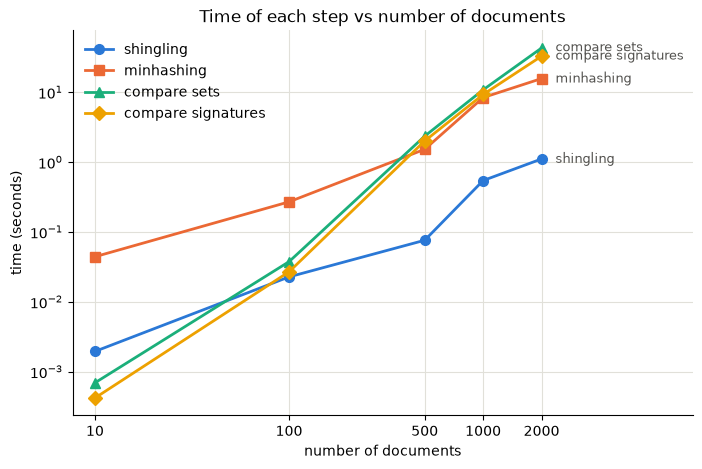

In [21]:
import matplotlib.pyplot as plt

# graph 1: time of each step vs number of documents
times_df = pd.DataFrame(results)   # not rounded, because a log scale can't show 0
steps = ["shingling (s)", "minhashing (s)", "compare sets (s)", "compare signatures (s)"]
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
markers = ["o", "s", "^", "D"]

fig, ax = plt.subplots(figsize=(8, 5))
for step, color, marker in zip(steps, colors, markers):
    name = step.replace(" (s)", "")
    ax.plot(times_df["documents"], times_df[step], color=color, marker=marker, linewidth=2, markersize=7, label=name)
    # write the name at the end of each line
    ax.annotate(name, (times_df["documents"].iloc[-1], times_df[step].iloc[-1]),
                xytext=(10, 0), textcoords="offset points", va="center", fontsize=9, color="#52514e")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(times_df["documents"])
ax.set_xticklabels(times_df["documents"])
ax.minorticks_off()
ax.set_xlim(right=times_df["documents"].max() * 6)   # space for the names at the end of the lines
ax.set_xlabel("number of documents")
ax.set_ylabel("time (seconds)")
ax.set_title("Time of each step vs number of documents")
ax.grid(True, color="#e1e0d9", linewidth=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="upper left", frameon=False)
plt.show()

499500 pairs
mean error: 0.0029
max error:  0.1315


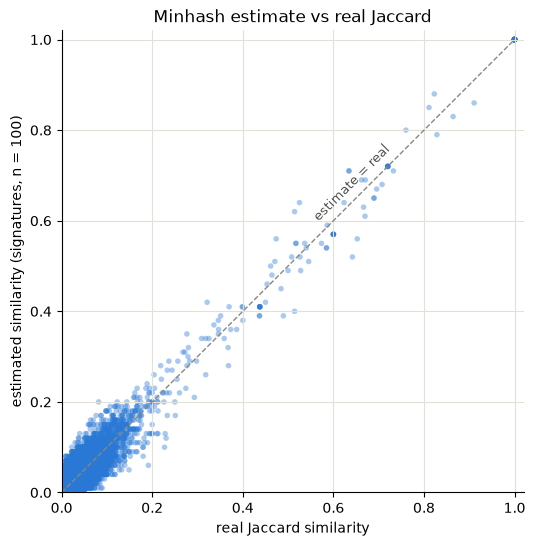

In [23]:
# graph 2: real Jaccard vs estimated similarity, for every pair of the first 500 documents
sample = docs[:1000]
shingle_sets = [Shingle(K, doc).hashes() for doc in sample]
minhashing = Minhashing(N_HASHES)
signatures = [minhashing.signature(hash_set) for hash_set in shingle_sets]

compare_sets = CompareSets()
compare_signatures = CompareSignatures()
real = []
estimated = []
for i in range(len(sample)):
    for j in range(i + 1, len(sample)):
        real.append(compare_sets.sim(shingle_sets[i], shingle_sets[j]))
        estimated.append(compare_signatures.sim(signatures[i], signatures[j]))

errors = [abs(r - e) for r, e in zip(real, estimated)]
print(len(real), "pairs")
print("mean error:", round(sum(errors) / len(errors), 4))
print("max error: ", round(max(errors), 4))

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(real, estimated, s=16, color="#2a78d6", alpha=0.4, edgecolors="none")
ax.plot([0, 1], [0, 1], color="#898781", linestyle="--", linewidth=1)   # diagonal: estimate = real
ax.annotate("estimate = real", (0.55, 0.60), rotation=45, color="#52514e", fontsize=9)
ax.set_aspect("equal")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
ax.set_xlabel("real Jaccard similarity")
ax.set_ylabel(f"estimated similarity (signatures, n = {N_HASHES})")
ax.set_title("Minhash estimate vs real Jaccard")
ax.grid(True, color="#e1e0d9", linewidth=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

## Results and conclusions

**Time (graph 1).** Shingling and minhashing grow linearly, because each document is done once. Compare sets and compare signatures grow quadratically, because they check every pair (with 2000 documents that is 2000 · 1999 / 2 ≈ 2 million pairs). For example, going from 1000 to 2000 documents, compare sets goes from 10.8 s to 42.9 s (about 4 times more).

With 2000 documents the slowest step is compare sets (42.9 s) and the whole run takes about 92 s. With all 5574 documents there would be about 8 times more pairs, so it would take around 10 minutes. To avoid comparing every pair we would need LSH.

**Quality of the estimate (graph 2 and table).** The estimate is very good: the dots are close to the diagonal and the mean error is 0.003. With 2000 documents there are only 4 false positives and 3 false negatives, and all of them have a Jaccard close to 0.8. This happens because the estimate has a small error, so a pair with 0.78 can be estimated as 0.82 and the other way around. With a bigger n there would be fewer mistakes.

**What was found.** Most similar pairs are spam messages sent many times with small changes, like a different phone number or a word in capital letters.

## AI disclosure

TO DOOOOOOO